# Análise Exploratória dos Dados — dataset `small`

**Inteligência Artificial 2026/27 — Grupo G05**

Análise exploratória do dataset `small`, usado no planeamento de rotas de recolha e distribuição de produtos locais (produtor → armazém → cliente).

**Objetivos (enunciado):**
1. Carregar os CSV e explorar os dados.
2. Validar a integridade dos dados e as janelas de tempo.
3. Comparar os pesos com as capacidades dos veículos.
4. Mostrar as paragens num mapa.

No fim, resumem-se as **implicações para a modelação** e para os algoritmos.

## 1. Carregar os CSV e explorar os dados

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)

# Pasta principal do projeto (funciona a partir da raiz ou da pasta notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = "data_small"
pasta = RAIZ / DATASET

# Ler todos os ficheiros CSV
tabelas = {f.stem: pd.read_csv(f) for f in sorted(pasta.glob("*.csv"))}
print("Dataset:", DATASET, "| ficheiros carregados:", len(tabelas))

pd.DataFrame([{"Tabela": nome, "Registos": len(df), "Colunas": ", ".join(df.columns)}
              for nome, df in tabelas.items()])

Dataset: data_small | ficheiros carregados: 12


,Tabela,Registos,Colunas
0,collection_centers,1,"center_id, name, locality_id, address, capacity_kg"
1,customers,21,"customer_id, name, locality_id, phone, email"
2,delivery_locations,7,"delivery_location_id, name, locality_id, address, location_type"
3,distance_matrix,182,"origin_location_id, origin_type, destination_location_id, destination_type, distance_km, duration_min"
4,localities,49,"locality_id, name, municipality, district, latitude, longitude"
5,locations,14,"location_id, location_type, ref_id, name, municipality, latitude, longitude"
6,order_items,80,"order_item_id, order_id, product_id, quantity, weight_kg, availability_start, availability_end, delivery_start, delivery_end"
7,orders,25,"order_id, customer_id, delivery_location_id, order_datetime, status"
8,producers,6,"producer_id, name, locality_id, address, phone, email"
9,products,31,"product_id, producer_id, name, category, unit, unit_weight_kg"


In [2]:
# Tabelas mais usadas
order_items = tabelas["order_items"].copy()
orders = tabelas["orders"]
products = tabelas["products"]
vehicles = tabelas["vehicles"]
locations = tabelas["locations"]
distance_matrix = tabelas["distance_matrix"]

# Datas das janelas de tempo
for coluna in ["availability_start", "availability_end", "delivery_start", "delivery_end"]:
    order_items[coluna] = pd.to_datetime(order_items[coluna])

# Juntar o produtor e o local de entrega a cada item
order_items = (order_items
               .merge(products[["product_id", "producer_id"]], on="product_id")
               .merge(orders[["order_id", "delivery_location_id"]], on="order_id"))
order_items.head()

,order_item_id,order_id,product_id,quantity,weight_kg,availability_start,availability_end,delivery_start,delivery_end,producer_id,delivery_location_id
0,1,1,12,12.0,12.0,2026-10-30 07:45:00,2026-10-30 10:45:00,2026-10-30 12:30:00,2026-10-30 14:30:00,3,5
1,2,1,30,7.4,7.4,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 12:30:00,2026-10-30 14:30:00,6,5
2,3,2,26,9.9,9.9,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 13:30:00,2026-10-30 16:45:00,6,4
3,4,2,18,17.9,17.9,2026-10-30 07:00:00,2026-10-30 09:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00,4,4
4,5,2,7,2.9,2.9,2026-10-30 08:45:00,2026-10-30 12:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00,2,4


**Como se ligam as tabelas:**
- `order_items` (itens) → `orders` (encomenda) → `delivery_locations` (onde se entrega) e `customers`;
- `order_items` → `products` → `producers` (onde se recolhe);
- `locations` junta produtores, armazém (`collection_center`) e locais de entrega num só identificador, usado na `distance_matrix`;
- `vehicles` → `collection_centers` (todos partem do mesmo armazém).

Cada **item** é uma unidade a transportar, com o seu peso, a **janela de recolha** (`availability_start`–`availability_end`) e a **janela de entrega** (`delivery_start`–`delivery_end`).

As **regras** do problema estão no `rules.csv`:

In [3]:
tabelas["rules"][["rule", "value", "description"]]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the warehouse
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arrival -> start of loading)
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


In [4]:
resumo = {
    "Produtores": len(tabelas["producers"]),
    "Produtos": len(products),
    "Clientes": len(tabelas["customers"]),
    "Locais de entrega": len(tabelas["delivery_locations"]),
    "Encomendas": len(orders),
    "Itens": len(order_items),
    "Veículos": len(vehicles),
    "Localizações (paragens)": len(locations),
}
pd.Series(resumo, name="Quantidade").to_frame()

,Quantidade
Produtores,6
Produtos,31
Clientes,21
Locais de entrega,7
Encomendas,25
Itens,80
Veículos,2
Localizações (paragens),14


## 2. Integridade dos dados

### 2.1 Valores em falta e duplicados

In [5]:
chaves = {"collection_centers": "center_id", "customers": "customer_id",
          "delivery_locations": "delivery_location_id", "localities": "locality_id",
          "locations": "location_id", "orders": "order_id", "order_items": "order_item_id",
          "producers": "producer_id", "products": "product_id", "vehicles": "vehicle_id",
          "rules": "rule"}

pd.DataFrame([{"Tabela": nome,
               "Valores em falta": int(df.isna().sum().sum()),
               "Linhas duplicadas": int(df.duplicated().sum()),
               "IDs duplicados": int(df[chaves[nome]].duplicated().sum()) if nome in chaves else 0}
              for nome, df in tabelas.items()])

,Tabela,Valores em falta,Linhas duplicadas,IDs duplicados
0,collection_centers,0,0,0
1,customers,0,0,0
2,delivery_locations,0,0,0
3,distance_matrix,0,0,0
4,localities,0,0,0
5,locations,0,0,0
6,order_items,0,0,0
7,orders,0,0,0
8,producers,0,0,0
9,products,0,0,0


### 2.2 Referências entre tabelas

In [6]:
relacoes = [("products", "producer_id", "producers", "producer_id"),
            ("order_items", "product_id", "products", "product_id"),
            ("order_items", "order_id", "orders", "order_id"),
            ("orders", "customer_id", "customers", "customer_id"),
            ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
            ("vehicles", "center_id", "collection_centers", "center_id")]
for tabela in ["producers", "customers", "delivery_locations", "collection_centers"]:
    relacoes.append((tabela, "locality_id", "localities", "locality_id"))

linhas = []
for origem, coluna, destino, chave in relacoes:
    invalidas = (~tabelas[origem][coluna].isin(tabelas[destino][chave])).sum()
    linhas.append({"Relação": f"{origem}.{coluna} → {destino}.{chave}", "Referências inválidas": int(invalidas)})

# Cada localização aponta para um produtor, armazém ou local de entrega que existe
tipos = {"producer": ("producers", "producer_id"),
         "collection_center": ("collection_centers", "center_id"),
         "delivery_location": ("delivery_locations", "delivery_location_id")}
for tipo, (tabela, chave) in tipos.items():
    pontos = locations[locations["location_type"] == tipo]
    linhas.append({"Relação": f"locations ({tipo}) → {tabela}",
                   "Referências inválidas": int((~pontos["ref_id"].isin(tabelas[tabela][chave])).sum())})
pd.DataFrame(linhas)

,Relação,Referências inválidas
0,products.producer_id → producers.producer_id,0
1,order_items.product_id → products.product_id,0
2,order_items.order_id → orders.order_id,0
3,orders.customer_id → customers.customer_id,0
4,orders.delivery_location_id → delivery_locations.delivery_location_id,0
5,vehicles.center_id → collection_centers.center_id,0
6,producers.locality_id → localities.locality_id,0
7,customers.locality_id → localities.locality_id,0
8,delivery_locations.locality_id → localities.locality_id,0
9,collection_centers.locality_id → localities.locality_id,0


### 2.3 Matriz de distâncias

In [7]:
ids = set(locations["location_id"])
pares_esperados = {(a, b) for a in ids for b in ids if a != b}
pares = set(zip(distance_matrix["origin_location_id"], distance_matrix["destination_location_id"]))

km = {(a, b): d for a, b, d in zip(distance_matrix["origin_location_id"],
                                   distance_matrix["destination_location_id"],
                                   distance_matrix["distance_km"])}
minutos = {(a, b): m for a, b, m in zip(distance_matrix["origin_location_id"],
                                        distance_matrix["destination_location_id"],
                                        distance_matrix["duration_min"])}

# Desigualdade triangular: ir de A a B passando por K é mais curto do que ir direto?
atalhos = sum(1 for a in ids for b in ids for k in ids
              if len({a, b, k}) == 3 and km[a, k] + km[k, b] < km[a, b] - 1e-9)

# O tempo de viagem corresponde à velocidade média das regras (45 km/h)?
com_distancia = distance_matrix[distance_matrix["distance_km"] > 0]
velocidade = com_distancia["distance_km"] / (com_distancia["duration_min"] / 60)

pd.Series({
    "Pares esperados": len(pares_esperados),
    "Pares existentes": len(pares),
    "Pares em falta": len(pares_esperados - pares),
    "Pares duplicados": int(distance_matrix.duplicated(["origin_location_id", "destination_location_id"]).sum()),
    "Valores negativos": int(((distance_matrix["distance_km"] < 0) | (distance_matrix["duration_min"] < 0)).sum()),
    "Pares assimétricos (ida ≠ volta)": sum(1 for a, b in pares if not np.isclose(km[a, b], km[b, a])),
    "Pares com distância 0": int((distance_matrix["distance_km"] == 0).sum()),
    "Atalhos (A→K→B mais curto que A→B)": atalhos,
    "Velocidade mínima (km/h)": round(velocidade.min(), 2),
    "Velocidade máxima (km/h)": round(velocidade.max(), 2),
}, name="Valor", dtype=object).to_frame()

,Valor
Pares esperados,182
Pares existentes,182
Pares em falta,0
Pares duplicados,0
Valores negativos,0
Pares assimétricos (ida ≠ volta),0
Pares com distância 0,4
Atalhos (A→K→B mais curto que A→B),6
Velocidade mínima (km/h),44.36
Velocidade máxima (km/h),45.16


In [8]:
# Que locais têm distância 0 entre si? (mesmas coordenadas)
repetidas = locations[locations.duplicated(["latitude", "longitude"], keep=False)]
repetidas[["location_id", "location_type", "name", "latitude", "longitude"]]

,location_id,location_type,name,latitude,longitude
3,4,producer,Courela Carvalho,41.531493,-8.446483
6,7,collection_center,Centro de Recolha 1,41.531493,-8.446483
7,8,delivery_location,Casa 1,41.610626,-8.367063
12,13,delivery_location,Loja 6,41.610626,-8.367063


**Leitura:** a matriz tem todos os pares origem-destino, sem duplicados, valores negativos ou diferenças entre ida e volta. Os tempos de viagem correspondem à velocidade média de 45 km/h indicada nas regras. As distâncias 0 são entre locais com as mesmas coordenadas (Courela Carvalho e Centro de Recolha 1; Casa 1 e Loja 6).

Há 6 casos em que passar por um terceiro local é mais curto do que ir direto. Por isso, nas heurísticas do A* usamos as distâncias mínimas entre locais (Floyd-Warshall), para garantir que a estimativa nunca exagera.

## 3. Janelas de tempo

### 3.1 Validade das janelas

In [9]:
inicio = pd.Timestamp(tabelas["rules"].set_index("rule").loc["start_date", "value"])
fim = inicio + pd.Timedelta(days=int(tabelas["rules"].set_index("rule").loc["horizon_days", "value"]))

recolha_h = (order_items["availability_end"] - order_items["availability_start"]).dt.total_seconds() / 3600
entrega_h = (order_items["delivery_end"] - order_items["delivery_start"]).dt.total_seconds() / 3600

pd.Series({
    "Datas inválidas": int(order_items[["availability_start", "availability_end",
                                        "delivery_start", "delivery_end"]].isna().sum().sum()),
    "Janelas de recolha com início > fim": int((recolha_h < 0).sum()),
    "Janelas de entrega com início > fim": int((entrega_h < 0).sum()),
    "Janelas fora do horizonte": int(((order_items["availability_start"] < inicio)
                                      | (order_items["delivery_end"] > fim)).sum()),
    "Entrega fecha antes de a recolha abrir": int((order_items["delivery_end"] <= order_items["availability_start"]).sum()),
    "Itens recolhidos e entregues em dias diferentes": int((order_items["availability_start"].dt.date
                                                             != order_items["delivery_start"].dt.date).sum()),
}, name="Valor", dtype=object).to_frame()

,Valor
Datas inválidas,0
Janelas de recolha com início > fim,0
Janelas de entrega com início > fim,0
Janelas fora do horizonte,0
Entrega fecha antes de a recolha abrir,0
Itens recolhidos e entregues em dias diferentes,20


In [10]:
pd.DataFrame({"Janela de recolha (h)": recolha_h, "Janela de entrega (h)": entrega_h}).agg(["min", "mean", "max"]).round(2)

,Janela de recolha (h),Janela de entrega (h)
min,1.50,1.50
mean,2.68,2.50
max,4.00,3.75


### 3.2 Encomendas

Uma encomenda é **carregada e entregue inteira**. Por isso, os itens da mesma encomenda têm de ter uma hora de entrega em comum.

In [11]:
por_encomenda = order_items.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    produtores=("producer_id", "nunique"),
    janelas_entrega=("delivery_start", "nunique"),
    abre=("delivery_start", "max"),
    fecha=("delivery_end", "min"))

pd.Series({
    "Encomendas": len(por_encomenda),
    "Itens por encomenda (mín–máx)": f"{por_encomenda['itens'].min()}–{por_encomenda['itens'].max()}",
    "Encomendas com itens de vários produtores": int((por_encomenda["produtores"] > 1).sum()),
    "Encomendas com a mesma janela de entrega em todos os itens": int((por_encomenda["janelas_entrega"] == 1).sum()),
    "Encomendas sem hora de entrega em comum": int((por_encomenda["abre"] > por_encomenda["fecha"]).sum()),
}, name="Valor", dtype=object).to_frame()

,Valor
Encomendas,25
Itens por encomenda (mín–máx),2–6
Encomendas com itens de vários produtores,25
Encomendas com a mesma janela de entrega em todos os itens,25
Encomendas sem hora de entrega em comum,0


### 3.3 Distribuição das janelas ao longo dos dois dias

Cada linha é um item: a azul a janela de recolha, a laranja a janela de entrega.

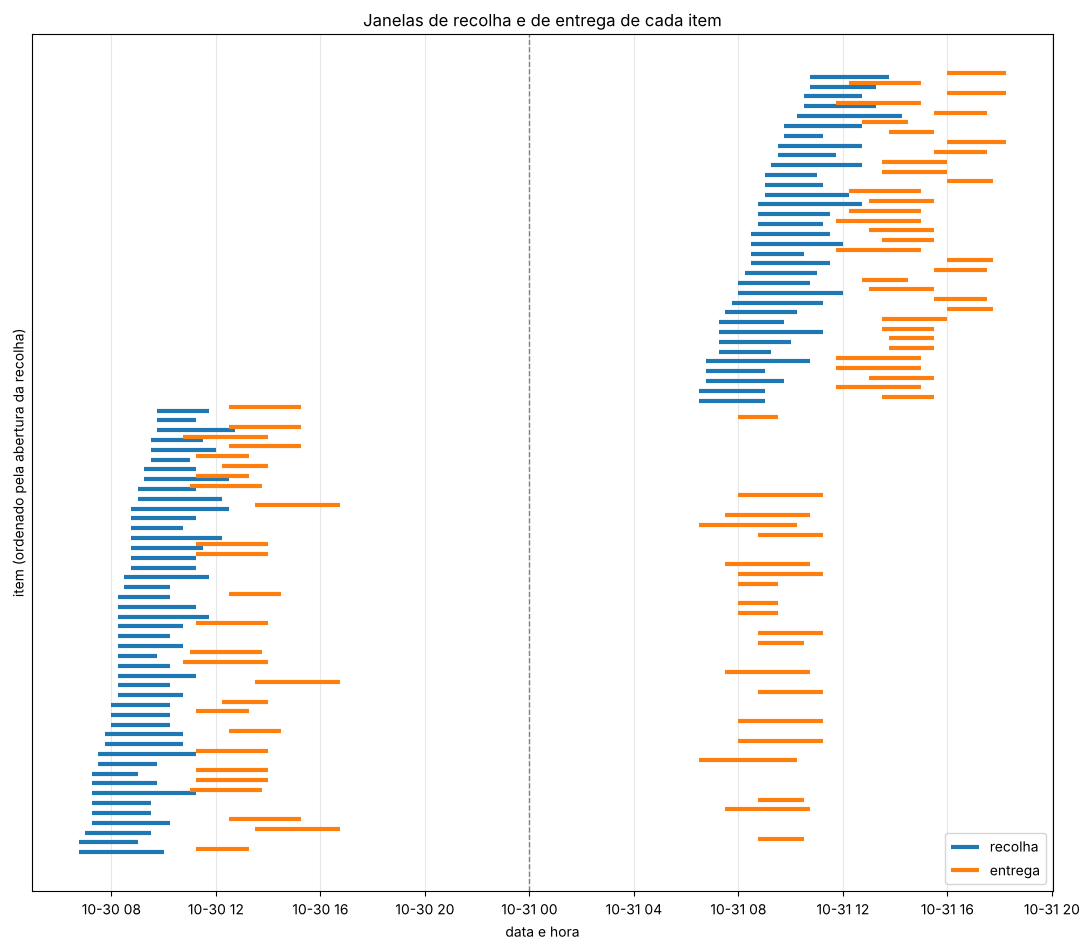

In [12]:
ordem = order_items.sort_values("availability_start").reset_index(drop=True)
fig, eixo = plt.subplots(figsize=(11, max(4, len(ordem) * 0.12)))
eixo.hlines(ordem.index, ordem["availability_start"], ordem["availability_end"], color="tab:blue", lw=3, label="recolha")
eixo.hlines(ordem.index + 0.35, ordem["delivery_start"], ordem["delivery_end"], color="tab:orange", lw=3, label="entrega")
eixo.axvline(inicio + pd.Timedelta(days=1), color="gray", ls="--", lw=1)
eixo.set_title("Janelas de recolha e de entrega de cada item")
eixo.set_xlabel("data e hora")
eixo.set_ylabel("item (ordenado pela abertura da recolha)")
eixo.set_yticks([])
eixo.legend(loc="lower right")
eixo.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.4 Permanência no armazém (máximo de 24 h)

Para cada item, o tempo mínimo que tem de esperar entre o fim da janela de recolha e o início da janela de entrega dá uma ideia de quanto tempo vai ficar no armazém. Se for maior do que 24 h, o item é impossível.

In [13]:
espera_min_h = (order_items["delivery_start"] - order_items["availability_end"]).dt.total_seconds() / 3600
noite = order_items["availability_start"].dt.date != order_items["delivery_start"].dt.date

pd.Series({
    "Itens que passam a noite no armazém": int(noite.sum()),
    "Espera mínima desses itens: menor valor (h)": round(espera_min_h[noite].min(), 2) if noite.any() else "—",
    "Espera mínima desses itens: maior valor (h)": round(espera_min_h[noite].max(), 2) if noite.any() else "—",
    "Itens com espera mínima > 24 h (impossíveis)": int((espera_min_h > 24).sum()),
}, name="Valor", dtype=object).to_frame()

,Valor
Itens que passam a noite no armazém,20
Espera mínima desses itens: menor valor (h),19.75
Espera mínima desses itens: maior valor (h),23.75
Itens com espera mínima > 24 h (impossíveis),0


### 3.5 Cada item é possível sozinho?

Teste otimista: um veículo sai do armazém no início do horizonte, recolhe só este item, volta ao armazém (descarga 15 min + carga 15 min) e vai entregar. Usa os tempos de serviço das regras e os tempos da matriz.

In [14]:
armazem = locations.loc[locations["location_type"] == "collection_center", "location_id"].iloc[0]
local_produtor = dict(zip(locations.loc[locations["location_type"] == "producer", "ref_id"],
                          locations.loc[locations["location_type"] == "producer", "location_id"]))
local_entrega = dict(zip(locations.loc[locations["location_type"] == "delivery_location", "ref_id"],
                         locations.loc[locations["location_type"] == "delivery_location", "location_id"]))
servico = pd.Timedelta(minutes=10)
armazem_min = pd.Timedelta(minutes=15)
viagem = lambda a, b: pd.Timedelta(minutes=0 if a == b else minutos[a, b])

folgas = []
for _, r in order_items.iterrows():
    P, D = local_produtor[r["producer_id"]], local_entrega[r["delivery_location_id"]]
    recolha = max(inicio + viagem(armazem, P), r["availability_start"])
    if recolha > r["availability_end"]:
        folgas.append(None)
        continue
    pronto = recolha + servico + viagem(P, armazem) + 2 * armazem_min     # descarregar + carregar
    entrega = max(pronto + viagem(armazem, D), r["delivery_start"])
    folgas.append((r["delivery_end"] - entrega).total_seconds() / 3600)
folgas = pd.Series(folgas, dtype=float)

pd.Series({
    "Itens possíveis sozinhos": int((folgas >= 0).sum()),
    "Itens impossíveis": int((folgas.isna() | (folgas < 0)).sum()),
    "Folga mínima na entrega (h)": round(folgas.min(), 2),
    "Folga média na entrega (h)": round(folgas.mean(), 2),
}, name="Valor", dtype=object).to_frame()

,Valor
Itens possíveis sozinhos,80
Itens impossíveis,0
Folga mínima na entrega (h),1.5
Folga média na entrega (h),2.48


## 4. Pesos e capacidades

In [15]:
peso_encomenda = order_items.groupby("order_id")["weight_kg"].sum()
peso_produtor = order_items.groupby("producer_id")["weight_kg"].sum()
peso_dia = order_items.groupby(order_items["availability_start"].dt.date)["weight_kg"].sum()
capacidades = vehicles.set_index("vehicle_id")["capacity_kg"]

pd.Series({
    "Itens com peso ≤ 0": int((order_items["weight_kg"] <= 0).sum()),
    "Peso total (kg)": round(order_items["weight_kg"].sum(), 1),
    "Capacidade dos veículos (kg)": " / ".join(f"{c:.0f}" for c in capacidades),
    "Capacidade dos dois juntos (kg)": round(capacidades.sum(), 1),
    "Peso total / capacidade conjunta": round(order_items["weight_kg"].sum() / capacidades.sum(), 2),
    "Encomenda mais pesada (kg)": round(peso_encomenda.max(), 1),
    "Encomendas acima do veículo mais pequeno": int((peso_encomenda > capacidades.min()).sum()),
    "Produtor com mais peso (kg)": round(peso_produtor.max(), 1),
    "Produtores com mais peso do que o veículo mais pequeno": int((peso_produtor > capacidades.min()).sum()),
}, name="Valor", dtype=object).to_frame()

,Valor
Itens com peso ≤ 0,0
Peso total (kg),580.0
Capacidade dos veículos (kg),250 / 300
Capacidade dos dois juntos (kg),550.0
Peso total / capacidade conjunta,1.05
Encomenda mais pesada (kg),38.4
Encomendas acima do veículo mais pequeno,0
Produtor com mais peso (kg),135.7
Produtores com mais peso do que o veículo mais pequeno,0


In [16]:
print("Peso a recolher por dia (kg):")
print(peso_dia.round(1).to_string())
print()
print(vehicles[["vehicle_id", "plate", "capacity_kg", "refrigerated", "avg_speed_kmh"]].to_string(index=False))

Peso a recolher por dia (kg):
availability_start
2026-10-30    338.7
2026-10-31    241.3

 vehicle_id    plate  capacity_kg  refrigerated  avg_speed_kmh
          1 ZG-06-DP        250.0             1           45.0
          2 TY-74-YA        300.0             0           45.0


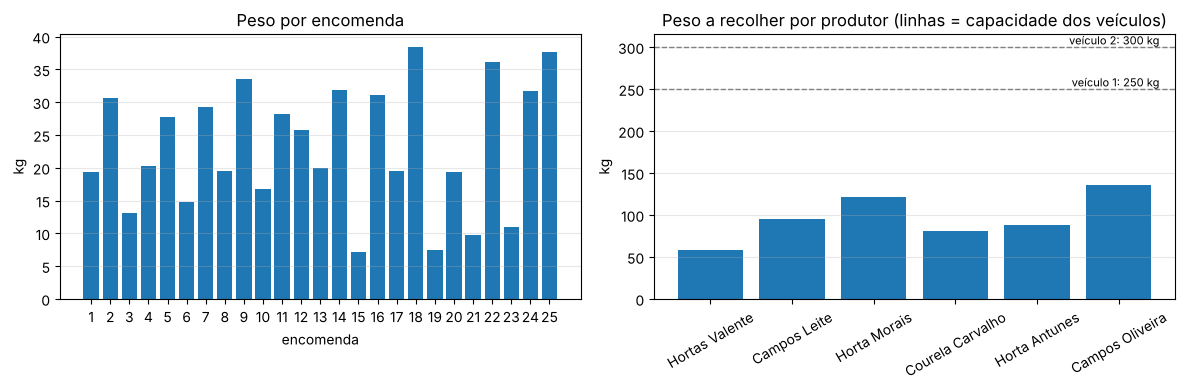

In [17]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].bar(peso_encomenda.index.astype(str), peso_encomenda.values)
eixos[0].set_title("Peso por encomenda")
eixos[0].set_xlabel("encomenda")
eixos[0].set_ylabel("kg")

nomes = tabelas["producers"].set_index("producer_id")["name"]
eixos[1].bar([nomes[p] for p in peso_produtor.index], peso_produtor.values)
for v, c in capacidades.items():
    eixos[1].axhline(c, ls="--", color="gray", lw=1)
    eixos[1].text(len(peso_produtor) - 0.5, c, f"veículo {v}: {c:.0f} kg", va="bottom", ha="right", fontsize=8)
eixos[1].set_title("Peso a recolher por produtor (linhas = capacidade dos veículos)")
eixos[1].set_ylabel("kg")
eixos[1].tick_params(axis="x", rotation=30)

for e in eixos:
    e.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Os veículos têm a coluna `refrigerated`, mas nenhum produto ou regra exige transporte refrigerado, por isso esta coluna não é usada no modelo.

## 5. Mapa das paragens

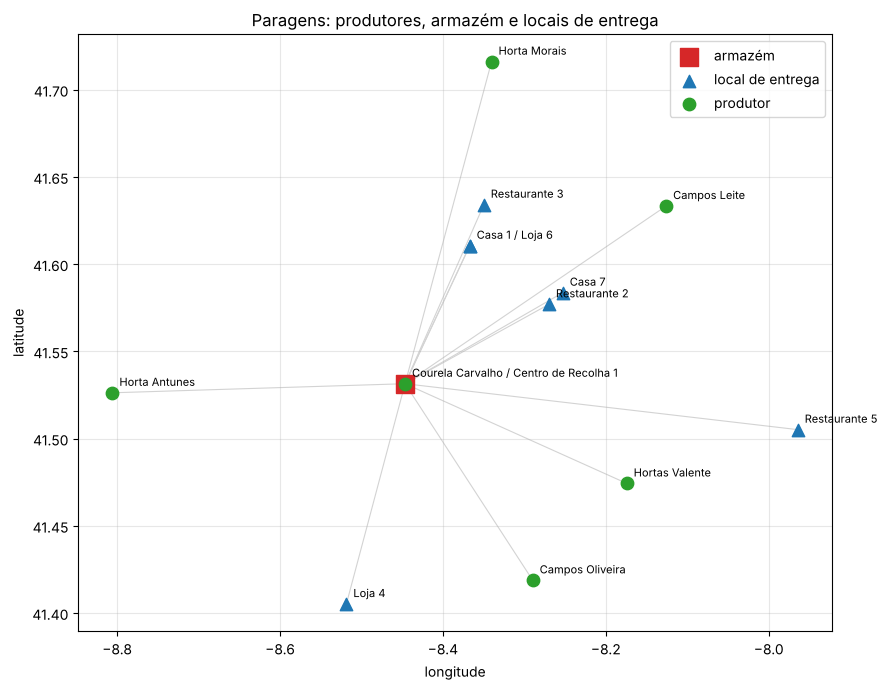

In [18]:
estilos = {"producer": ("tab:green", "o", "produtor"),
           "collection_center": ("tab:red", "s", "armazém"),
           "delivery_location": ("tab:blue", "^", "local de entrega")}
fig, eixo = plt.subplots(figsize=(9, 7))
for tipo, grupo in locations.groupby("location_type"):
    cor, marcador, legenda = estilos[tipo]
    eixo.scatter(grupo["longitude"], grupo["latitude"], c=cor, marker=marcador,
                 s=160 if tipo == "collection_center" else 80, label=legenda, zorder=3)

# Nomes (locais com as mesmas coordenadas ficam juntos num só rótulo)
for (lon, lat), grupo in locations.groupby(["longitude", "latitude"]):
    eixo.annotate(" / ".join(grupo["name"]), (lon, lat), textcoords="offset points",
                  xytext=(5, 5), fontsize=8)

# Linhas armazém → produtor e armazém → cliente (o percurso obrigatório)
a = locations[locations["location_type"] == "collection_center"].iloc[0]
for _, r in locations[locations["location_type"] != "collection_center"].iterrows():
    eixo.plot([a["longitude"], r["longitude"]], [a["latitude"], r["latitude"]],
              color="lightgray", lw=0.8, zorder=1)

eixo.set_title("Paragens: produtores, armazém e locais de entrega")
eixo.set_xlabel("longitude")
eixo.set_ylabel("latitude")
eixo.legend()
eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Distância de cada paragem ao armazém
d = pd.DataFrame({"Paragem": locations["name"], "Tipo": locations["location_type"],
                  "km ao armazém": [0.0 if i == armazem else km[armazem, i] for i in locations["location_id"]]})
d[d["Tipo"] != "collection_center"].sort_values("km ao armazém").reset_index(drop=True)

,Paragem,Tipo,km ao armazém
0,Courela Carvalho,producer,0.00
1,Casa 1,delivery_location,14.30
2,Loja 6,delivery_location,14.30
3,Restaurante 3,delivery_location,18.16
4,Loja 4,delivery_location,19.85
5,Restaurante 2,delivery_location,20.22
6,Casa 7,delivery_location,22.27
7,Campos Oliveira,producer,23.53
8,Horta Morais,producer,29.06
9,Hortas Valente,producer,30.60


## 6. Conclusões

**Dados.** O dataset `small` tem 6 produtores, 7 locais de entrega, 25 encomendas, 80 itens e 2 veículos (250 e 300 kg). Não há valores em falta, duplicados nem referências inválidas, e a matriz de distâncias está completa e simétrica.

**Janelas de tempo.** Todas as janelas são válidas e estão dentro do horizonte. São curtas: em média 2,68 h para recolher e 2,50 h para entregar. Todos os itens de uma encomenda têm a mesma janela de entrega. 20 itens são recolhidos num dia e entregues no outro. Mesmo sem contar viagens e tempos de serviço, esses itens têm de esperar entre 19,75 h e 23,75 h — muito perto das 24 h, por isso a regra das 24 h no armazém é apertada: obriga a recolhê-los perto do fim da janela e a carregá-los cedo no dia seguinte. Testado isoladamente, **todos os itens são possíveis** (um veículo sozinho consegue recolher e entregar cada item a tempo).

**Pesos.** Nenhuma encomenda ultrapassa sozinha a capacidade de um veículo (a mais pesada tem 38,4 kg). O peso total (580,0 kg) é maior do que a capacidade dos dois veículos juntos (550,0 kg) — mesmo que tudo estivesse disponível ao mesmo tempo, seria preciso mais do que uma viagem.

**Paragens.** 14 localizações. Têm as mesmas coordenadas (distância 0): Courela Carvalho e Centro de Recolha 1; Casa 1 e Loja 6.

### Implicações para a modelação
- **Várias viagens por veículo:** as recolhas estão espalhadas pelos dois dias e as janelas são curtas, por isso cada veículo tem de fazer várias viagens (no CSP, as variáveis são "veículo + nº da viagem").
- **Passagem pelo armazém e encomendas inteiras:** 25 de 25 encomendas têm itens de vários produtores, que só se juntam no armazém; o modelo carrega e entrega sempre a encomenda completa.
- **Ordem no tempo:** com janelas curtas, a ordem das paragens é muito limitada. Por isso o Greedy só olha para movimentos nas próximas horas e o CSP decide primeiro as tarefas mais urgentes.
- **24 h no armazém:** os itens que passam a noite obrigam a verificar a permanência, o que é feito no `model.py` ao carregar.
- **Capacidade:** controla-se a carga acumulada ao longo da rota, e não só por encomenda.